In [1]:
import stim

In [ ]:
"""Written out Shor Code."""
# Used to understand structure of Shor code and how it works.

# Initialize error rates
p_pheno = 0.005
p_gate = 0.005
p_idle = 0.005
p_measure = 0.005

circuit = stim.Circuit(f'''

# -- Initialize all data qubits (0-8) and the ancilla qubit (9) --

R 0 1 2 3 4 5 6 7 8 9

# -- Layer 1 --
CX 0 3
DEPOLARIZE2({p_gate}) 0 3
DEPOLARIZE1({p_idle}) 1 2 4 5 6 7 8 9
TICK

CX 0 6
DEPOLARIZE2({p_gate}) 0 6
DEPOLARIZE1({p_idle}) 1 2 3 4 5 7 8 9
TICK

H 0 3 6
DEPOLARIZE1({p_gate}) 0 3 6
DEPOLARIZE1({p_idle}) 1 2 4 5 7 8 9
TICK

# -- Layer 2 --

CX 0 1
DEPOLARIZE2({p_gate}) 0 1
CX 3 4
DEPOLARIZE2({p_gate}) 3 4
CX 6 7
DEPOLARIZE2({p_gate}) 6 7
DEPOLARIZE1({p_idle}) 2 5 8 9
TICK

CX 0 2
DEPOLARIZE2({p_gate}) 0 2
CX 3 5
DEPOLARIZE2({p_gate}) 3 5
CX 6 8
DEPOLARIZE2({p_gate}) 6 8
DEPOLARIZE1({p_idle}) 1 4 7 9
TICK

# -- Encode for errors using phenomenological noise --
DEPOLARIZE1({p_pheno}) 0 1 2 3 4 5 6 7 8
TICK

# -- Bit flip stabilizers --

# Z0Z1
## Layer 1
CX 0 9
DEPOLARIZE2({p_gate}) 0 9
DEPOLARIZE1({p_idle}) 1 2 3 4 5 6 7 8
TICK

## Layer 2
CX 1 9
DEPOLARIZE2({p_gate}) 1 9
DEPOLARIZE1({p_idle}) 0 2 3 4 5 6 7 8
TICK

## Measurement
X_ERROR({p_measure}) 9
MR 9
DETECTOR rec[-1]
TICK

# Z1Z2
## Layer 1
CX 1 9
DEPOLARIZE2({p_gate}) 1 9
DEPOLARIZE1({p_idle}) 0 2 3 4 5 6 7 8
TICK

## Layer 2
CX 2 9
DEPOLARIZE2({p_gate}) 2 9
DEPOLARIZE1({p_idle}) 0 1 3 4 5 6 7 8
TICK

## Measurement
X_ERROR({p_measure}) 9
MR 9
DETECTOR rec[-1]
TICK

# Z3Z4
## Layer 1
CX 3 9
DEPOLARIZE2({p_gate}) 3 9
DEPOLARIZE1({p_idle}) 0 1 2 4 5 6 7 8
TICK

## Layer 2
CX 4 9
DEPOLARIZE2({p_gate}) 4 9
DEPOLARIZE1({p_idle}) 0 1 2 3 5 6 7 8
TICK

## Measurement
X_ERROR({p_measure}) 9
MR 9
DETECTOR rec[-1]
TICK

# Z4Z5
## Layer 1
CX 4 9
DEPOLARIZE2({p_gate}) 4 9
DEPOLARIZE1({p_idle}) 0 1 2 3  5 6 7 8
TICK

## Layer 2
CX 5 9
DEPOLARIZE2({p_gate}) 5 9
DEPOLARIZE1({p_idle}) 0 1 2 3 4 6 7 8
TICK

## Measurement
X_ERROR({p_measure}) 9
MR 9
DETECTOR rec[-1]
TICK

# Z6Z7
## Layer 1
CX 6 9
DEPOLARIZE2({p_gate}) 6 9
DEPOLARIZE1({p_idle}) 0 1 2 3 4 5 7 8
TICK

## Layer 2
CX 7 9
DEPOLARIZE2({p_gate}) 7 9
DEPOLARIZE1({p_idle}) 0 1 2 3 4 5 6 8
TICK

## Measurement
X_ERROR({p_measure}) 9
MR 9
DETECTOR rec[-1]
TICK

# Z7Z8
## Layer 1
CX 7 9
DEPOLARIZE2({p_gate}) 7 9
DEPOLARIZE1({p_idle}) 0 1 2 3 4 5 6 8
TICK

## Layer 2
CX 8 9
DEPOLARIZE2({p_gate}) 8 9
DEPOLARIZE1({p_idle}) 0 1 2 3 4 5 6 7
TICK

## Measurement
X_ERROR({p_measure}) 9
MR 9
DETECTOR rec[-1]
TICK

# -- Phase flip stabilizers --

# X0X1X2X3X4X5
H 0 1 2 3 4 5
DEPOLARIZE1({p_gate}) 0 1 2 3 4 5
DEPOLARIZE1({p_idle}) 6 7 8 9
TICK

CX 0 9
DEPOLARIZE2({p_gate}) 0 9
DEPOLARIZE1({p_idle}) 1 2 3 4 5 6 7 8
TICK

CX 1 9
DEPOLARIZE2({p_gate}) 1 9
DEPOLARIZE1({p_idle}) 0 2 3 4 5 6 7 8
TICK

CX 2 9
DEPOLARIZE2({p_gate}) 2 9
DEPOLARIZE1({p_idle}) 0 1 3 4 5 6 7 8
TICK

CX 3 9
DEPOLARIZE2({p_gate}) 3 9
DEPOLARIZE1({p_idle}) 0 1 2 4 5 6 7 8
TICK

CX 4 9
DEPOLARIZE2({p_gate}) 4 9
DEPOLARIZE1({p_idle}) 0 1 2 3 5 6 7 8
TICK

CX 5 9
DEPOLARIZE2({p_gate}) 5 9
DEPOLARIZE1({p_idle}) 0 1 2 3 4 6 7 8
TICK

H 0 1 2 3 4 5
DEPOLARIZE1({p_gate}) 0 1 2 3 4 5
DEPOLARIZE1({p_idle}) 6 7 8 9
TICK

X_ERROR({p_measure}) 9
MR 9
DETECTOR rec[-1]
TICK

# X3X4X5X6X7X8
H 3 4 5 6 7 8
DEPOLARIZE1({p_gate}) 3 4 5 6 7 8
DEPOLARIZE1({p_idle}) 0 1 2 9
TICK

CX 3 9
DEPOLARIZE2({p_gate}) 3 9
DEPOLARIZE1({p_idle}) 0 1 2 4 5 6 7 8
TICK

CX 4 9
DEPOLARIZE2({p_gate}) 4 9
DEPOLARIZE1({p_idle}) 0 1 2 3 5 6 7 8
TICK

CX 5 9
DEPOLARIZE2({p_gate}) 5 9
DEPOLARIZE1({p_idle}) 0 1 2 3 4 6 7 8
TICK

CX 6 9
DEPOLARIZE2({p_gate}) 6 9
DEPOLARIZE1({p_idle}) 0 1 2 3 4 5 7 8
TICK

CX 7 9
DEPOLARIZE2({p_gate}) 7 9
DEPOLARIZE1({p_idle}) 0 1 2 3 4 5 6 8
TICK

CX 8 9
DEPOLARIZE2({p_gate}) 8 9
DEPOLARIZE1({p_idle}) 0 1 2 3 4 5 6 7
TICK

H 3 4 5 6 7 8
DEPOLARIZE1({p_gate}) 3 4 5 6 7 8
DEPOLARIZE1({p_idle}) 0 1 2 9
TICK

X_ERROR({p_measure}) 9
MR 9
DETECTOR rec[-1]
TICK
'''
)

In [ ]:
circuit = stim.Circuit()

# Intialize error rates
p_pheno = 0.005
p_gate = 0.005
p_idle = 0.005
p_measure = 0.005

# Initialize all data qubits (0-8) and the ancilla qubit (9)
circuit.append("R", range(10))

# Encode a state as 3 qubits (layer 1)
circuit.append("CX", [0, 3])
circuit.append("DEPOLARIZE2", [0, 3], p_gate)
circuit.append("DEPOLARIZE1", [1, 2, 4, 5, 6, 7, 8, 9], p_idle)
circuit.append("TICK")

circuit.append("CX", [0, 6])
circuit.append("DEPOLARIZE2", [0, 6], p_gate)
circuit.append("DEPOLARIZE1", [1, 2, 3, 4, 5, 7, 8, 9], p_idle)
circuit.append("TICK")

circuit.append("H", [0, 3, 6])
circuit.append("DEPOLARIZE1", [0, 3, 6], p_gate)
circuit.append("DEPOLARIZE1", [1, 2, 4, 5, 7, 8, 9], p_idle)
circuit.append("TICK")

# Concatenation (layer 2)
blocks = [(0, 1, 2), (3, 4, 5), (6, 7, 8)]

## First CX layer (to ensure parallelness)
for control, target1, target2 in blocks:
    circuit.append("CX", [control, target1])
    circuit.append("DEPOLARIZE2", [control, target1], p_gate)
circuit.append("DEPOLARIZE1", [2, 5, 8, 9], p_idle)
circuit.append("TICK")

## Second CX layer
for control, target1, target2 in blocks:
    circuit.append("CX", [control, target2])
    circuit.append("DEPOLARIZE2", [control, target2], p_gate)
circuit.append("DEPOLARIZE1", [1, 4, 7, 9], p_idle)
circuit.append("TICK")

# Phenomenological noise
circuit.append("DEPOLARIZE1", range(9), p_pheno)
circuit.append("TICK")

# Bit-flip (Z) stabilizers
z_stabilizers = [
    (0, 1), (1, 2),
    (3, 4), (4, 5),
    (6, 7), (7, 8)
]

for control1, control2 in z_stabilizers:
    # First CX layer
    circuit.append("CX", [control1, 9])
    circuit.append("DEPOLARIZE2", [control1, 9], p_gate)
    idle = [q for q in range(10) if q not in {control1, 9}]
    circuit.append("DEPOLARIZE1", idle, p_idle)
    circuit.append("TICK")

    # Second CX layer
    circuit.append("CX", [control2, 9])
    circuit.append("DEPOLARIZE2", [control2, 9], p_gate)
    idle = [q for q in range(10) if q not in {control2, 9}]
    circuit.append("DEPOLARIZE1", idle, p_idle)
    circuit.append("TICK")

    # Measurement
    circuit.append("X_ERROR", [9], p_measure)
    circuit.append("MR", [9])
    circuit.append("DEPOLARIZE1", range(9), p_idle)
    circuit.append("DETECTOR", [stim.target_rec(-1)])
    circuit.append("TICK")

# Phase-flip (X) stabilizers
x_stabilizers = [
    (0, 1, 2, 3, 4, 5),
    (3, 4, 5, 6, 7, 8)
]

for stabilizer in x_stabilizers:
    # First Hadamard layer
    circuit.append("H", stabilizer)
    circuit.append("DEPOLARIZE1", stabilizer, p_gate)
    idle = [q for q in range(10) if q not in stabilizer]
    circuit.append("DEPOLARIZE1", idle, p_idle)
    circuit.append("TICK")

    # CX gates
    for control in stabilizer:
        circuit.append("CX", [control, 9])
        circuit.append("DEPOLARIZE2", [control, 9], p_gate)
        idle = [q for q in range(10) if q not in {control, 9}]
        circuit.append("DEPOLARIZE1", idle, p_idle)
        circuit.append("TICK")

    # Second Hadamard layer
    circuit.append("H", stabilizer)
    circuit.append("DEPOLARIZE1", stabilizer, p_gate)
    idle = [q for q in range(10) if q not in stabilizer]
    circuit.append("DEPOLARIZE1", idle, p_idle)
    circuit.append("TICK")

    # Measurement
    circuit.append("X_ERROR", [9], p_measure)
    circuit.append("MR", [9])
    circuit.append("DEPOLARIZE1", range(9), p_idle)
    circuit.append("DETECTOR", [stim.target_rec(-1)])
    circuit.append("TICK")

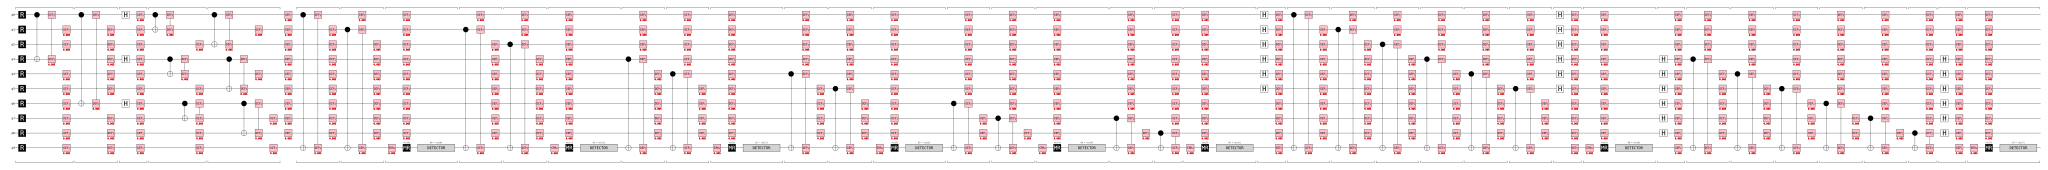

In [10]:
"""Circuit diagram for Shor code."""

circuit.diagram('timeline-svg')

In [15]:
"""Returns the detector measurements from the Shor code."""

runs = 10_000

sampler = circuit.compile_detector_sampler()
print(sampler.sample(shots=runs))

[[False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]
 ...
 [False False False ... False False False]
 [False False False ... False False False]
 [False False False ... False False False]]
